In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Зареждане на всички резултати
results_mean_df = pd.read_csv("data/results_mean.csv")
results_hist_df = pd.read_csv("data/results_hist.csv")
results_knn_df  = pd.read_csv("data/results_knn.csv")
results_rf_df   = pd.read_csv("data/results_rf.csv")
results_vae_df  = pd.read_csv("data/results_vae.csv")
results_gan_df  = pd.read_csv("data/results_gan.csv")

# Добавяме колона за метод
results_mean_df["method"] = "Mean"
results_hist_df["method"] = "Hist Avg"
results_knn_df["method"]  = "KNN"
results_rf_df["method"]   = "Random Forest"
results_vae_df["method"]  = "VAE"
results_gan_df["method"]  = "GAN"

# Обединяваме всички
all_results = pd.concat([
    results_mean_df, results_hist_df, results_knn_df,
    results_rf_df,   results_vae_df,  results_gan_df
]).reset_index(drop=True)

print("=" * 60)
print("ОБОБЩЕНИЕ НА ВСИЧКИ МЕТОДИ")
print("=" * 60)
print(f"Методи   : {all_results['method'].unique().tolist()}")
print(f"Периоди  : {all_results['period'].unique().tolist()}")
print(f"\nСредно MAE и RMSE по метод:")
summary = (all_results.groupby("method")[["MAE","RMSE"]]
           .mean()
           .round(2)
           .sort_values("MAE"))
print(summary.to_string())

ОБОБЩЕНИЕ НА ВСИЧКИ МЕТОДИ
Методи   : ['Mean', 'Hist Avg', 'KNN', 'Random Forest', 'VAE', 'GAN']
Периоди  : ['short_1', 'short_2', 'short_3', 'medium_1', 'medium_2', 'medium_3', 'long_1', 'long_2', 'long_3']

Средно MAE и RMSE по метод:
                  MAE    RMSE
method                       
GAN            116.46  149.47
VAE            117.90  179.01
Random Forest  118.67  149.76
KNN            139.88  177.85
Hist Avg       197.68  241.56
Mean           327.37  377.79


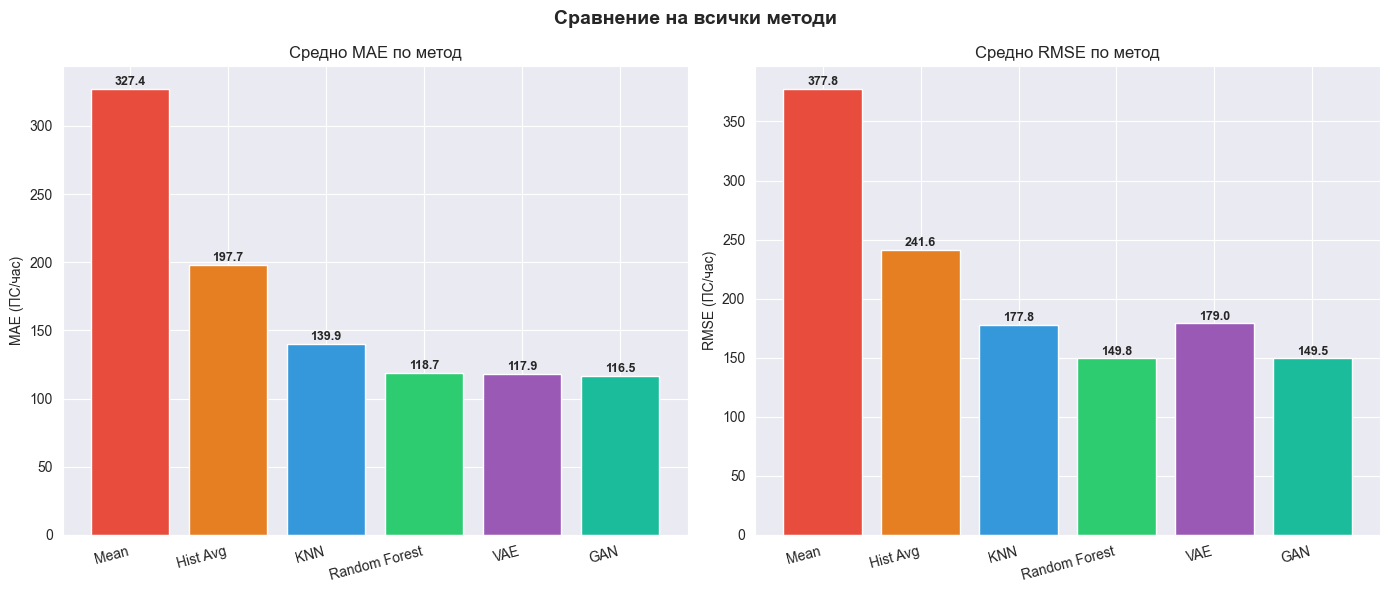

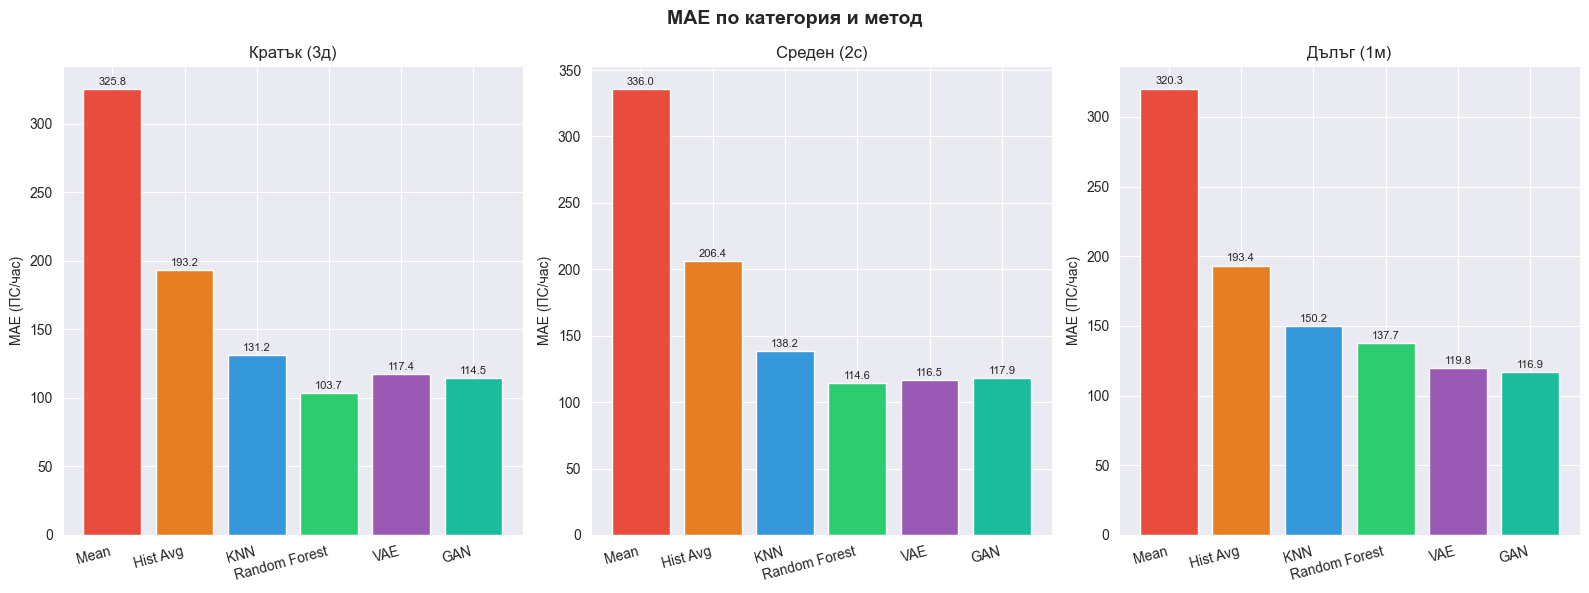

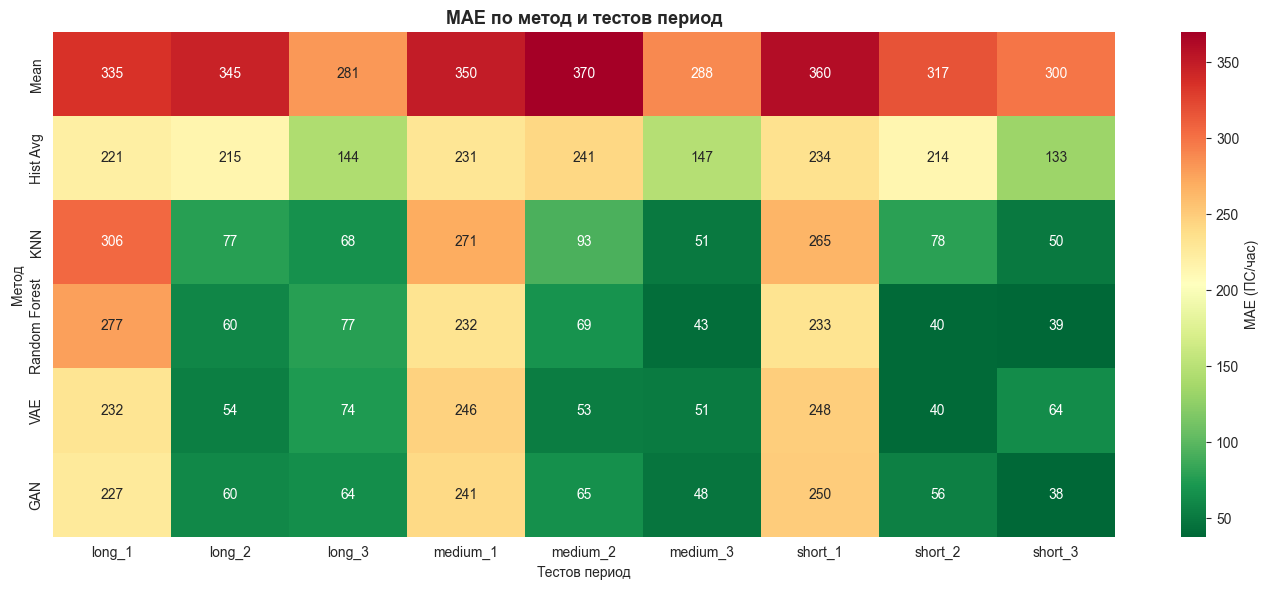

In [3]:
# Визуализация 1 — Общо сравнение MAE и RMSE по метод
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Сравнение на всички методи", fontsize=14, fontweight="bold")

methods = ["Mean", "Hist Avg", "KNN", "Random Forest", "VAE", "GAN"]
colors  = ["#e74c3c", "#e67e22", "#3498db", "#2ecc71", "#9b59b6", "#1abc9c"]

mae_vals  = [all_results[all_results["method"]==m]["MAE"].mean()  for m in methods]
rmse_vals = [all_results[all_results["method"]==m]["RMSE"].mean() for m in methods]

x = np.arange(len(methods))

bars1 = ax1.bar(x, mae_vals, color=colors, edgecolor="white")
ax1.set_title("Средно MAE по метод")
ax1.set_ylabel("MAE (ПС/час)")
ax1.set_xticks(x)
ax1.set_xticklabels(methods, rotation=15, ha="right")
for bar, val in zip(bars1, mae_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             f"{val:.1f}", ha="center", fontsize=9, fontweight="bold")

bars2 = ax2.bar(x, rmse_vals, color=colors, edgecolor="white")
ax2.set_title("Средно RMSE по метод")
ax2.set_ylabel("RMSE (ПС/час)")
ax2.set_xticks(x)
ax2.set_xticklabels(methods, rotation=15, ha="right")
for bar, val in zip(bars2, rmse_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             f"{val:.1f}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("comparison_overall.png", dpi=150, bbox_inches="tight")
plt.show()

# Визуализация 2 — MAE по категория и метод
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle("MAE по категория и метод", fontsize=14, fontweight="bold")

categories = {"short": "Кратък (3д)", "medium": "Среден (2с)", "long": "Дълъг (1м)"}

for ax, (cat, cat_label) in zip(axes, categories.items()):
    cat_data = all_results[all_results["category"] == cat]
    mae_vals = [cat_data[cat_data["method"]==m]["MAE"].mean() for m in methods]
    
    bars = ax.bar(x, mae_vals, color=colors, edgecolor="white")
    ax.set_title(cat_label)
    ax.set_ylabel("MAE (ПС/час)")
    ax.set_xticks(x)
    ax.set_xticklabels(methods, rotation=15, ha="right")
    for bar, val in zip(bars, mae_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
                f"{val:.1f}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("comparison_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

# Визуализация 3 — Heatmap на MAE по метод и период
fig, ax = plt.subplots(figsize=(14, 6))

pivot = all_results.pivot(index="method", columns="period", values="MAE")
pivot = pivot.reindex(methods)

sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn_r",
            ax=ax, cbar_kws={"label": "MAE (ПС/час)"})
ax.set_title("MAE по метод и тестов период", fontsize=13, fontweight="bold")
ax.set_xlabel("Тестов период")
ax.set_ylabel("Метод")

plt.tight_layout()
plt.savefig("comparison_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

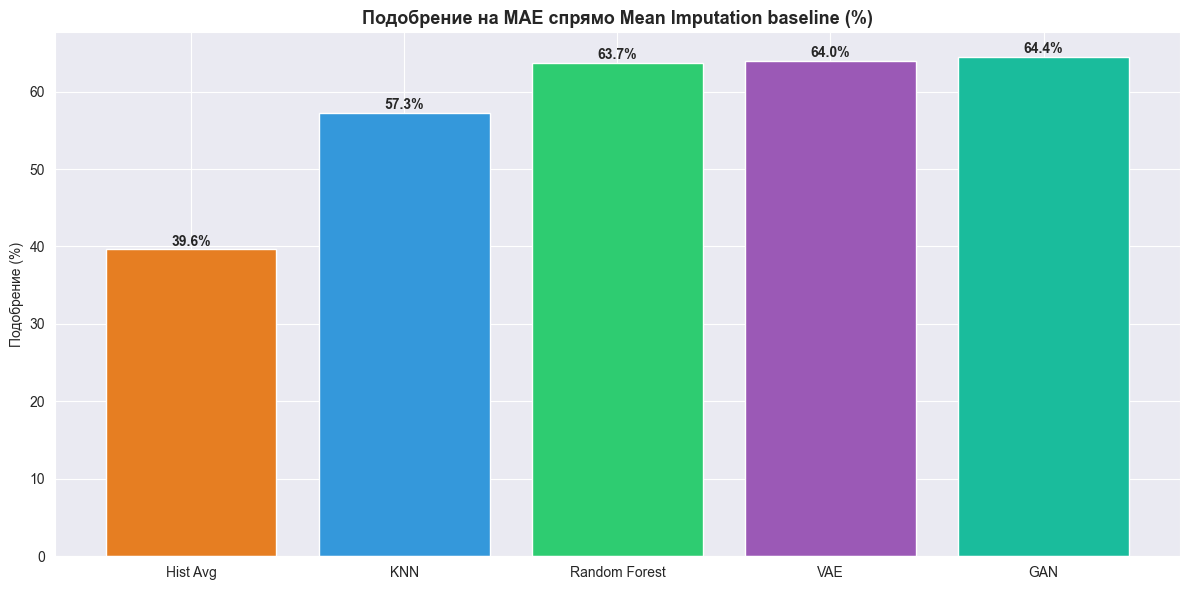

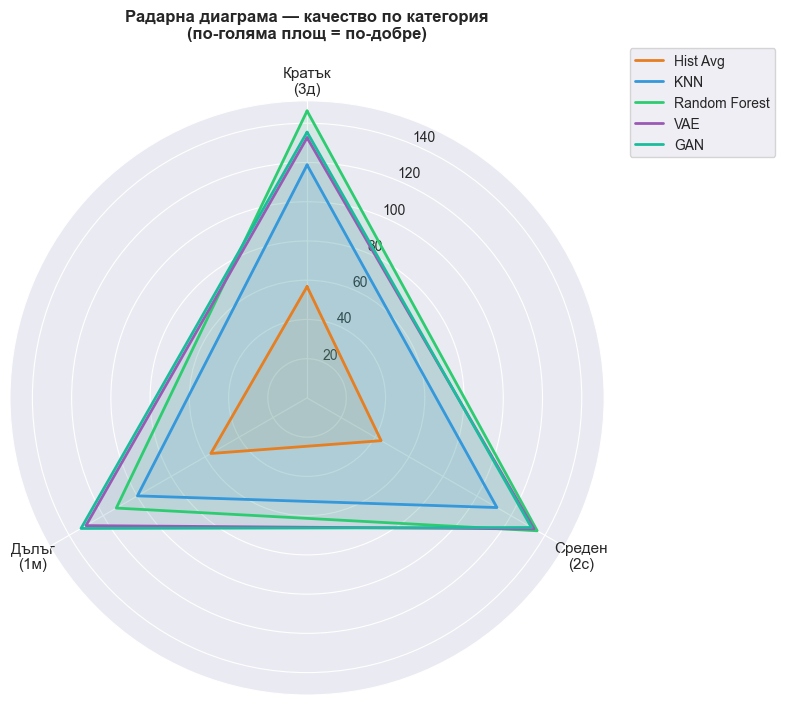

In [4]:
# Визуализация 4 — Подобрение спрямо baseline (Mean)
fig, ax = plt.subplots(figsize=(12, 6))

methods_no_mean = ["Hist Avg", "KNN", "Random Forest", "VAE", "GAN"]
colors_no_mean  = ["#e67e22", "#3498db", "#2ecc71", "#9b59b6", "#1abc9c"]
mean_mae_base   = all_results[all_results["method"]=="Mean"]["MAE"].mean()

improvements = []
for m in methods_no_mean:
    m_mae = all_results[all_results["method"]==m]["MAE"].mean()
    improvements.append((mean_mae_base - m_mae) / mean_mae_base * 100)

x = np.arange(len(methods_no_mean))
bars = ax.bar(x, improvements, color=colors_no_mean, edgecolor="white")
ax.set_title("Подобрение на MAE спрямо Mean Imputation baseline (%)",
             fontsize=13, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(methods_no_mean)
ax.set_ylabel("Подобрение (%)")
ax.axhline(y=0, color="white", linewidth=0.5)

for bar, val in zip(bars, improvements):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{val:.1f}%", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("comparison_improvement.png", dpi=150, bbox_inches="tight")
plt.show()

# Визуализация 5 — Радарна диаграма
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

categories_radar = ["Кратък\n(3д)", "Среден\n(2с)", "Дълъг\n(1м)"]
N = len(categories_radar)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories_radar, fontsize=11)

methods_radar = ["Hist Avg", "KNN", "Random Forest", "VAE", "GAN"]
colors_radar  = ["#e67e22", "#3498db", "#2ecc71", "#9b59b6", "#1abc9c"]

# Нормализираме MAE (по-малко = по-добре, обръщаме скалата)
max_mae = 250
for method, color in zip(methods_radar, colors_radar):
    values = []
    for cat in ["short", "medium", "long"]:
        mae = all_results[
            (all_results["method"]==method) & 
            (all_results["category"]==cat)
        ]["MAE"].mean()
        # Обръщаме — по-висока стойност = по-добре
        values.append(max_mae - mae)
    values += values[:1]
    ax.plot(angles, values, linewidth=2, color=color, label=method)
    ax.fill(angles, values, alpha=0.1, color=color)

ax.set_title("Радарна диаграма — качество по категория\n(по-голяма площ = по-добре)",
             fontsize=12, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))

plt.tight_layout()
plt.savefig("comparison_radar.png", dpi=150, bbox_inches="tight")
plt.show()

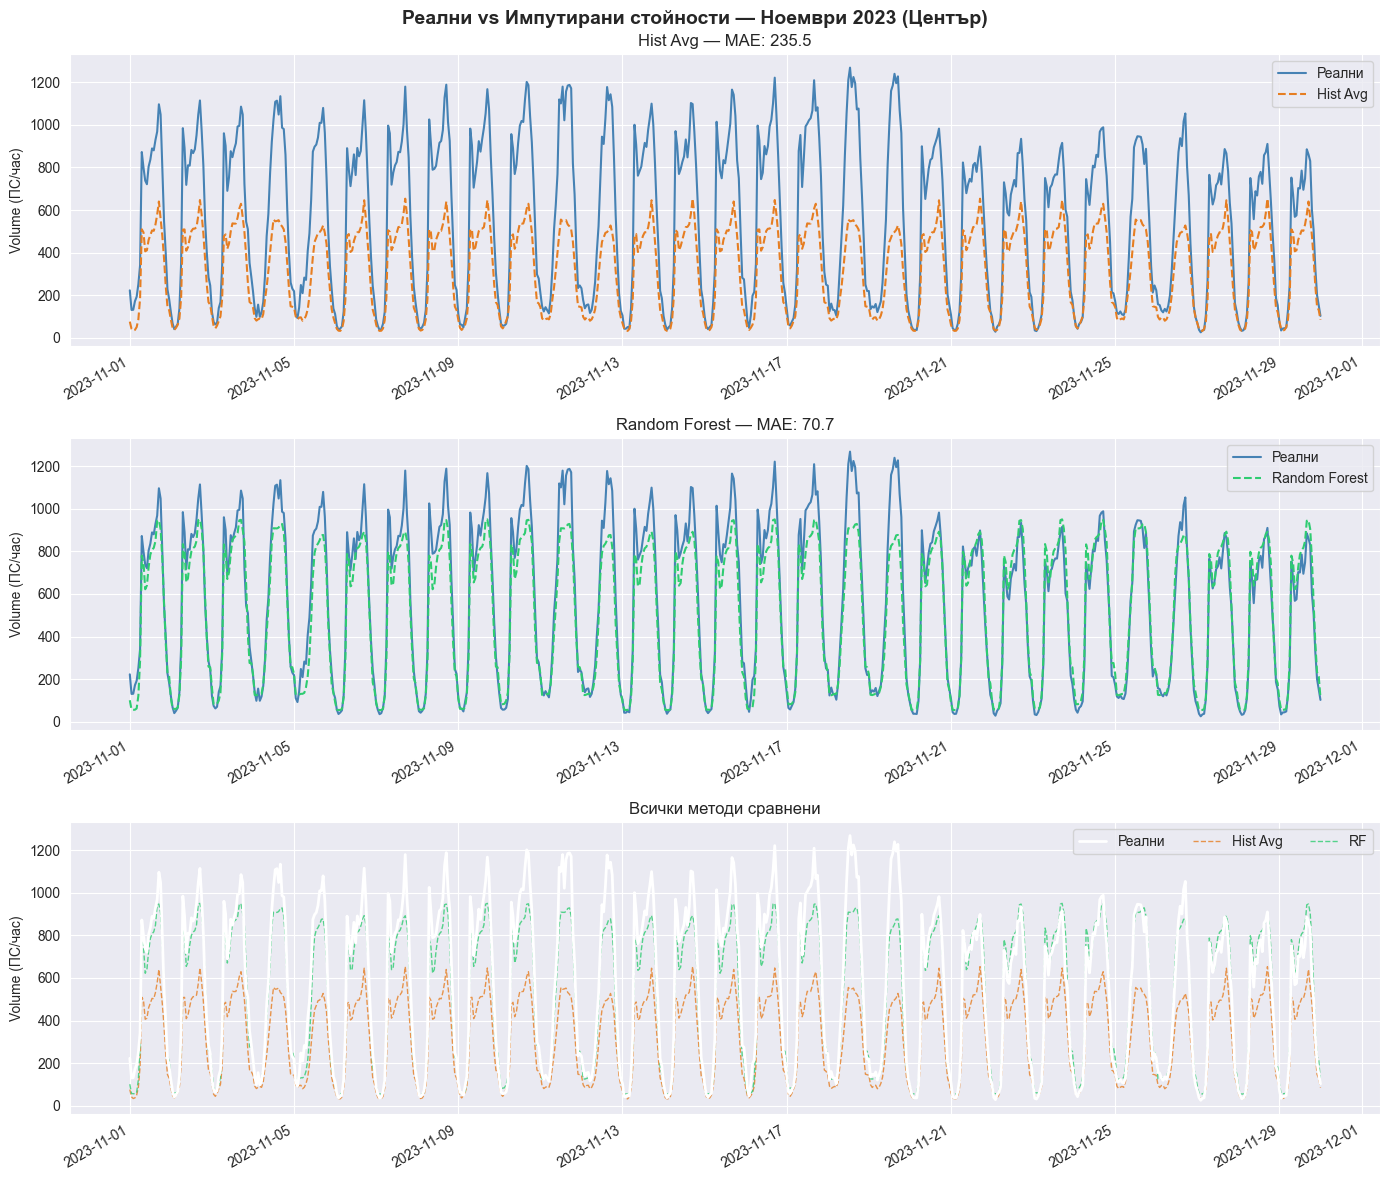

In [5]:
# Визуализация 6 — Реални vs Импутирани за всички методи
# Използваме long_2 (Ноември 2023) като най-представителен период

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

# Зареждаме aggregated data
df = pd.read_csv("data/traffic_aggregated.csv", parse_dates=["datetime"])
df["hour"]          = df["datetime"].dt.hour
df["dow"]           = df["datetime"].dt.dayofweek
df["month"]         = df["datetime"].dt.month
df["direction_enc"] = (df["direction"] == "Център").astype(int)
df["hour_sin"]      = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]      = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"]       = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"]       = np.cos(2 * np.pi * df["dow"] / 7)
df["month_sin"]     = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"]     = np.cos(2 * np.pi * df["month"] / 12)

feature_cols = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
                "month_sin", "month_cos", "direction_enc"]

start, end   = "2023-11-01", "2023-11-30"
train_data   = df[
    ((df["datetime"] < start) | (df["datetime"] > end)) &
    df["volume"].notna()
].copy()

X_train = train_data[feature_cols].values.astype(np.float32)
y_train = train_data["volume"].values.astype(np.float32).reshape(-1, 1)

scaler         = StandardScaler()
y_train_scaled = scaler.fit_transform(y_train)

# Тестов период
mask    = (df["datetime"] >= start) & (df["datetime"] <= end)
test_df = df[mask].copy().reset_index(drop=True)
test_df["volume_true"] = test_df["volume"]
test_df["volume"]      = np.nan

# Само Център посока
test_center = test_df[test_df["direction"] == "Център"].copy()

# 1. Historical Average
profile = (train_data.groupby(["dow", "hour", "direction"])["volume"]
           .mean().reset_index().rename(columns={"volume": "vol_hist"}))
test_center = test_center.merge(profile, on=["dow","hour","direction"], how="left")

# 2. Random Forest
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train.ravel())
test_center["vol_rf"] = rf.predict(
    test_center[feature_cols].values.astype(np.float32)
)

# Визуализация
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle("Реални vs Импутирани стойности — Ноември 2023 (Център)",
             fontsize=14, fontweight="bold")

method_data = [
    ("vol_hist", "Hist Avg",     "#e67e22"),
    ("vol_rf",   "Random Forest","#2ecc71"),
]

for ax, (col, label, color) in zip(axes[:2], method_data):
    ax.plot(test_center["datetime"], test_center["volume_true"],
            color="steelblue", linewidth=1.5, label="Реални")
    ax.plot(test_center["datetime"], test_center[col],
            color=color, linewidth=1.5, linestyle="--", label=label)
    ax.set_ylabel("Volume (ПС/час)")
    ax.legend()
    ax.set_title(f"{label} — MAE: "
                 f"{np.mean(np.abs(test_center['volume_true'] - test_center[col])):.1f}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

# Сравнение на всички методи в един subplot
axes[2].plot(test_center["datetime"], test_center["volume_true"],
             color="white", linewidth=2, label="Реални", zorder=5)
axes[2].plot(test_center["datetime"], test_center["vol_hist"],
             color="#e67e22", linewidth=1, linestyle="--", alpha=0.8, label="Hist Avg")
axes[2].plot(test_center["datetime"], test_center["vol_rf"],
             color="#2ecc71", linewidth=1, linestyle="--", alpha=0.8, label="RF")
axes[2].set_ylabel("Volume (ПС/час)")
axes[2].set_title("Всички методи сравнени")
axes[2].legend(ncol=3)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.setp(axes[2].xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("comparison_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Mean импутация
mean_by_direction = df[df["volume"].notna()].groupby("direction")["volume"].mean()
test_center["vol_mean"] = mean_by_direction["Център"]

# Historical Average импутация
train_for_hist = df[
    ((df["datetime"] < start) | (df["datetime"] > end)) &
    (df["volume"].notna()) &
    (df["direction"] == "Център")
].copy()

profile = (train_for_hist.groupby(["dow", "hour"])["volume"]
           .mean()
           .reset_index()
           .rename(columns={"volume": "vol_hist"}))

test_center = test_center.merge(profile, on=["dow", "hour"], how="left")

print("Проверка на всички импутирани колони:")
method_cols = ["vol_mean", "vol_hist", "vol_knn", "vol_rf", "vol_vae", "vol_gan"]
for col in method_cols:
    if col in test_center.columns:
        mae = np.mean(np.abs(test_center["volume_true"] - test_center[col]))
        print(f"  {col:<12}: MAE={mae:.1f}")
    else:
        print(f"  {col:<12}: липсва")

Проверка на всички импутирани колони:
  vol_mean    : MAE=369.3
  vol_hist    : липсва
  vol_knn     : липсва
  vol_rf      : MAE=70.7
  vol_vae     : липсва
  vol_gan     : липсва


In [7]:
# Проверка на колоните в test_center
print("Налични колони:")
print(test_center.columns.tolist())

# Проверка за dow и hour
print(f"\ndow в test_center: {'dow' in test_center.columns}")
print(f"hour в test_center: {'hour' in test_center.columns}")
print(f"\nПример от test_center:")
print(test_center[["datetime", "direction", "volume_true", "dow", "hour"]].head(6).to_string())

Налични колони:
['datetime', 'direction', 'volume', 'avg_speed', 'hour', 'dow', 'month', 'direction_enc', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'volume_true', 'vol_hist_x', 'vol_rf', 'vol_mean', 'vol_hist_y']

dow в test_center: True
hour в test_center: True

Пример от test_center:
             datetime direction  volume_true  dow  hour
0 2023-11-01 00:00:00    Център        223.0    2     0
1 2023-11-01 01:00:00    Център        131.0    2     1
2 2023-11-01 02:00:00    Център        132.0    2     2
3 2023-11-01 03:00:00    Център        172.0    2     3
4 2023-11-01 04:00:00    Център        193.0    2     4
5 2023-11-01 05:00:00    Център        252.0    2     5


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================================
# VAE АРХИТЕКТУРА
# ============================================================
class ConditionalVAE(nn.Module):
    def __init__(self, input_dim, condition_dim, latent_dim, hidden_dims):
        super(ConditionalVAE, self).__init__()
        self.latent_dim = latent_dim
        encoder_layers  = []
        in_dim = input_dim + condition_dim
        for h_dim in hidden_dims:
            encoder_layers.extend([
                nn.Linear(in_dim, h_dim), nn.ReLU(),
                nn.BatchNorm1d(h_dim), nn.Dropout(0.1)
            ])
            in_dim = h_dim
        self.encoder   = nn.Sequential(*encoder_layers)
        self.fc_mu     = nn.Linear(hidden_dims[-1], latent_dim)
        self.fc_logvar = nn.Linear(hidden_dims[-1], latent_dim)
        decoder_layers = []
        in_dim = latent_dim + condition_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers.extend([
                nn.Linear(in_dim, h_dim), nn.ReLU(),
                nn.BatchNorm1d(h_dim), nn.Dropout(0.1)
            ])
            in_dim = h_dim
        decoder_layers.append(nn.Linear(hidden_dims[0], input_dim))
        self.decoder = nn.Sequential(*decoder_layers)

    def encode(self, x, c):
        h = self.encoder(torch.cat([x, c], dim=1))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def decode(self, z, c):
        return self.decoder(torch.cat([z, c], dim=1))

    def forward(self, x, c):
        mu, logvar = self.encode(x, c)
        z          = self.reparameterize(mu, logvar)
        return self.decode(z, c), mu, logvar

def vae_loss(recon_x, x, mu, logvar, beta=1.0):
    recon_loss = nn.MSELoss()(recon_x, x)
    kl_loss    = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + beta * kl_loss, recon_loss, kl_loss

# ============================================================
# GAN АРХИТЕКТУРА
# ============================================================
class Generator(nn.Module):
    def __init__(self, noise_dim, condition_dim, hidden_dims):
        super(Generator, self).__init__()
        layers = []
        in_dim = noise_dim + condition_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(in_dim, h_dim), nn.LeakyReLU(0.2),
                nn.BatchNorm1d(h_dim), nn.Dropout(0.1)
            ])
            in_dim = h_dim
        layers.append(nn.Linear(hidden_dims[-1], 1))
        self.model = nn.Sequential(*layers)

    def forward(self, noise, condition):
        return self.model(torch.cat([noise, condition], dim=1))

class Discriminator(nn.Module):
    def __init__(self, condition_dim, hidden_dims):
        super(Discriminator, self).__init__()
        layers = []
        in_dim = 1 + condition_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(in_dim, h_dim), nn.LeakyReLU(0.2),
                nn.Dropout(0.3)
            ])
            in_dim = h_dim
        layers.extend([nn.Linear(hidden_dims[-1], 1), nn.Sigmoid()])
        self.model = nn.Sequential(*layers)

    def forward(self, x, condition):
        return self.model(torch.cat([x, condition], dim=1))

# DataLoader за обучение
X_tensor = torch.FloatTensor(X_train).to(device)
y_tensor = torch.FloatTensor(y_train_scaled).to(device)
dataset  = TensorDataset(y_tensor, X_tensor)
loader   = DataLoader(dataset, batch_size=64, shuffle=True)

print("Архитектурите са дефинирани")
print(f"Устройство: {device}")

Архитектурите са дефинирани
Устройство: cuda


In [10]:
# Нулираме test_center
mask        = (df["datetime"] >= start) & (df["datetime"] <= end)
test_df     = df[mask].copy().reset_index(drop=True)
test_df["volume_true"] = test_df["volume"]
test_df["volume"]      = np.nan
test_center = test_df[test_df["direction"] == "Център"].copy().reset_index(drop=True)

print(f"test_center редове: {len(test_center)}")
print(f"Колони: {test_center.columns.tolist()}")

# 1. Mean
mean_val = df[
    (df["volume"].notna()) & (df["direction"] == "Център")
]["volume"].mean()
test_center["vol_mean"] = mean_val

# 2. Historical Average
train_hist = df[
    ((df["datetime"] < start) | (df["datetime"] > end)) &
    (df["volume"].notna()) &
    (df["direction"] == "Център")
].copy()

profile = (train_hist.groupby(["dow", "hour"])["volume"]
           .mean()
           .reset_index()
           .rename(columns={"volume": "vol_hist"}))

test_center = test_center.merge(profile, on=["dow", "hour"], how="left")

# 3. KNN
from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor(n_neighbors=50, metric="euclidean")
knn.fit(X_train, y_train.ravel())
test_center["vol_knn"] = knn.predict(
    test_center[feature_cols].values.astype(np.float32)
)

# 4. Random Forest
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train.ravel())
test_center["vol_rf"] = rf.predict(
    test_center[feature_cols].values.astype(np.float32)
)

# 5. VAE
vae_model = ConditionalVAE(1, len(feature_cols), 8, [2048, 1024, 512]).to(device)
vae_opt   = optim.Adam(vae_model.parameters(), lr=0.001)

vae_model.train()
print("Обучаване на VAE...")
for epoch in range(200):
    for y_batch, x_batch in loader:
        vae_opt.zero_grad()
        recon, mu, logvar = vae_model(y_batch, x_batch)
        loss, _, _        = vae_loss(recon, y_batch, mu, logvar)
        loss.backward()
        vae_opt.step()
    if (epoch + 1) % 50 == 0:
        print(f"  Epoch {epoch+1}/200")

vae_model.eval()
with torch.no_grad():
    X_test  = torch.FloatTensor(
        test_center[feature_cols].values.astype(np.float32)
    ).to(device)
    samples = []
    for _ in range(50):
        z      = torch.randn(len(X_test), 8).to(device)
        output = vae_model.decode(z, X_test)
        samples.append(output.cpu().numpy())
    mean_output = np.mean(samples, axis=0)
    test_center["vol_vae"] = np.maximum(
        scaler.inverse_transform(mean_output), 0
    ).flatten()

# 6. GAN
G_model = Generator(32, len(feature_cols), [256, 128, 64]).to(device)
D_model = Discriminator(len(feature_cols), [128, 64]).to(device)
opt_G   = optim.Adam(G_model.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_D   = optim.Adam(D_model.parameters(), lr=0.0001, betas=(0.5, 0.999))
criterion = nn.BCELoss()

print("Обучаване на GAN...")
for epoch in range(400):
    for y_real, x_cond in loader:
        batch_size  = y_real.size(0)
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        opt_D.zero_grad()
        d_real  = D_model(y_real, x_cond)
        noise   = torch.randn(batch_size, 32).to(device)
        y_fake  = G_model(noise, x_cond)
        d_loss  = (criterion(d_real, real_labels) +
                   criterion(D_model(y_fake.detach(), x_cond), fake_labels)) / 2
        d_loss.backward()
        opt_D.step()

        opt_G.zero_grad()
        noise  = torch.randn(batch_size, 32).to(device)
        y_fake = G_model(noise, x_cond)
        g_loss = criterion(D_model(y_fake, x_cond), real_labels)
        g_loss.backward()
        opt_G.step()

    if (epoch + 1) % 100 == 0:
        print(f"  Epoch {epoch+1}/400")

G_model.eval()
with torch.no_grad():
    X_test  = torch.FloatTensor(
        test_center[feature_cols].values.astype(np.float32)
    ).to(device)
    samples = []
    for _ in range(50):
        noise  = torch.randn(len(X_test), 32).to(device)
        output = G_model(noise, X_test)
        samples.append(output.cpu().numpy())
    mean_output = np.mean(samples, axis=0)
    test_center["vol_gan"] = np.maximum(
        scaler.inverse_transform(mean_output), 0
    ).flatten()

# Проверка
print("\nПроверка на всички импутирани колони:")
method_cols = ["vol_mean", "vol_hist", "vol_knn", "vol_rf", "vol_vae", "vol_gan"]
for col in method_cols:
    if col in test_center.columns:
        mae = np.mean(np.abs(test_center["volume_true"] - test_center[col]))
        print(f"  {col:<12}: MAE={mae:.1f}")
    else:
        print(f"  {col:<12}: липсва")

test_center редове: 697
Колони: ['datetime', 'direction', 'volume', 'avg_speed', 'hour', 'dow', 'month', 'direction_enc', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'volume_true']
Обучаване на VAE...
  Epoch 50/200
  Epoch 100/200
  Epoch 150/200
  Epoch 200/200
Обучаване на GAN...
  Epoch 100/400
  Epoch 200/400
  Epoch 300/400
  Epoch 400/400

Проверка на всички импутирани колони:
  vol_mean    : MAE=369.3
  vol_hist    : MAE=235.5
  vol_knn     : MAE=91.6
  vol_rf      : MAE=70.7
  vol_vae     : MAE=78.5
  vol_gan     : MAE=85.1


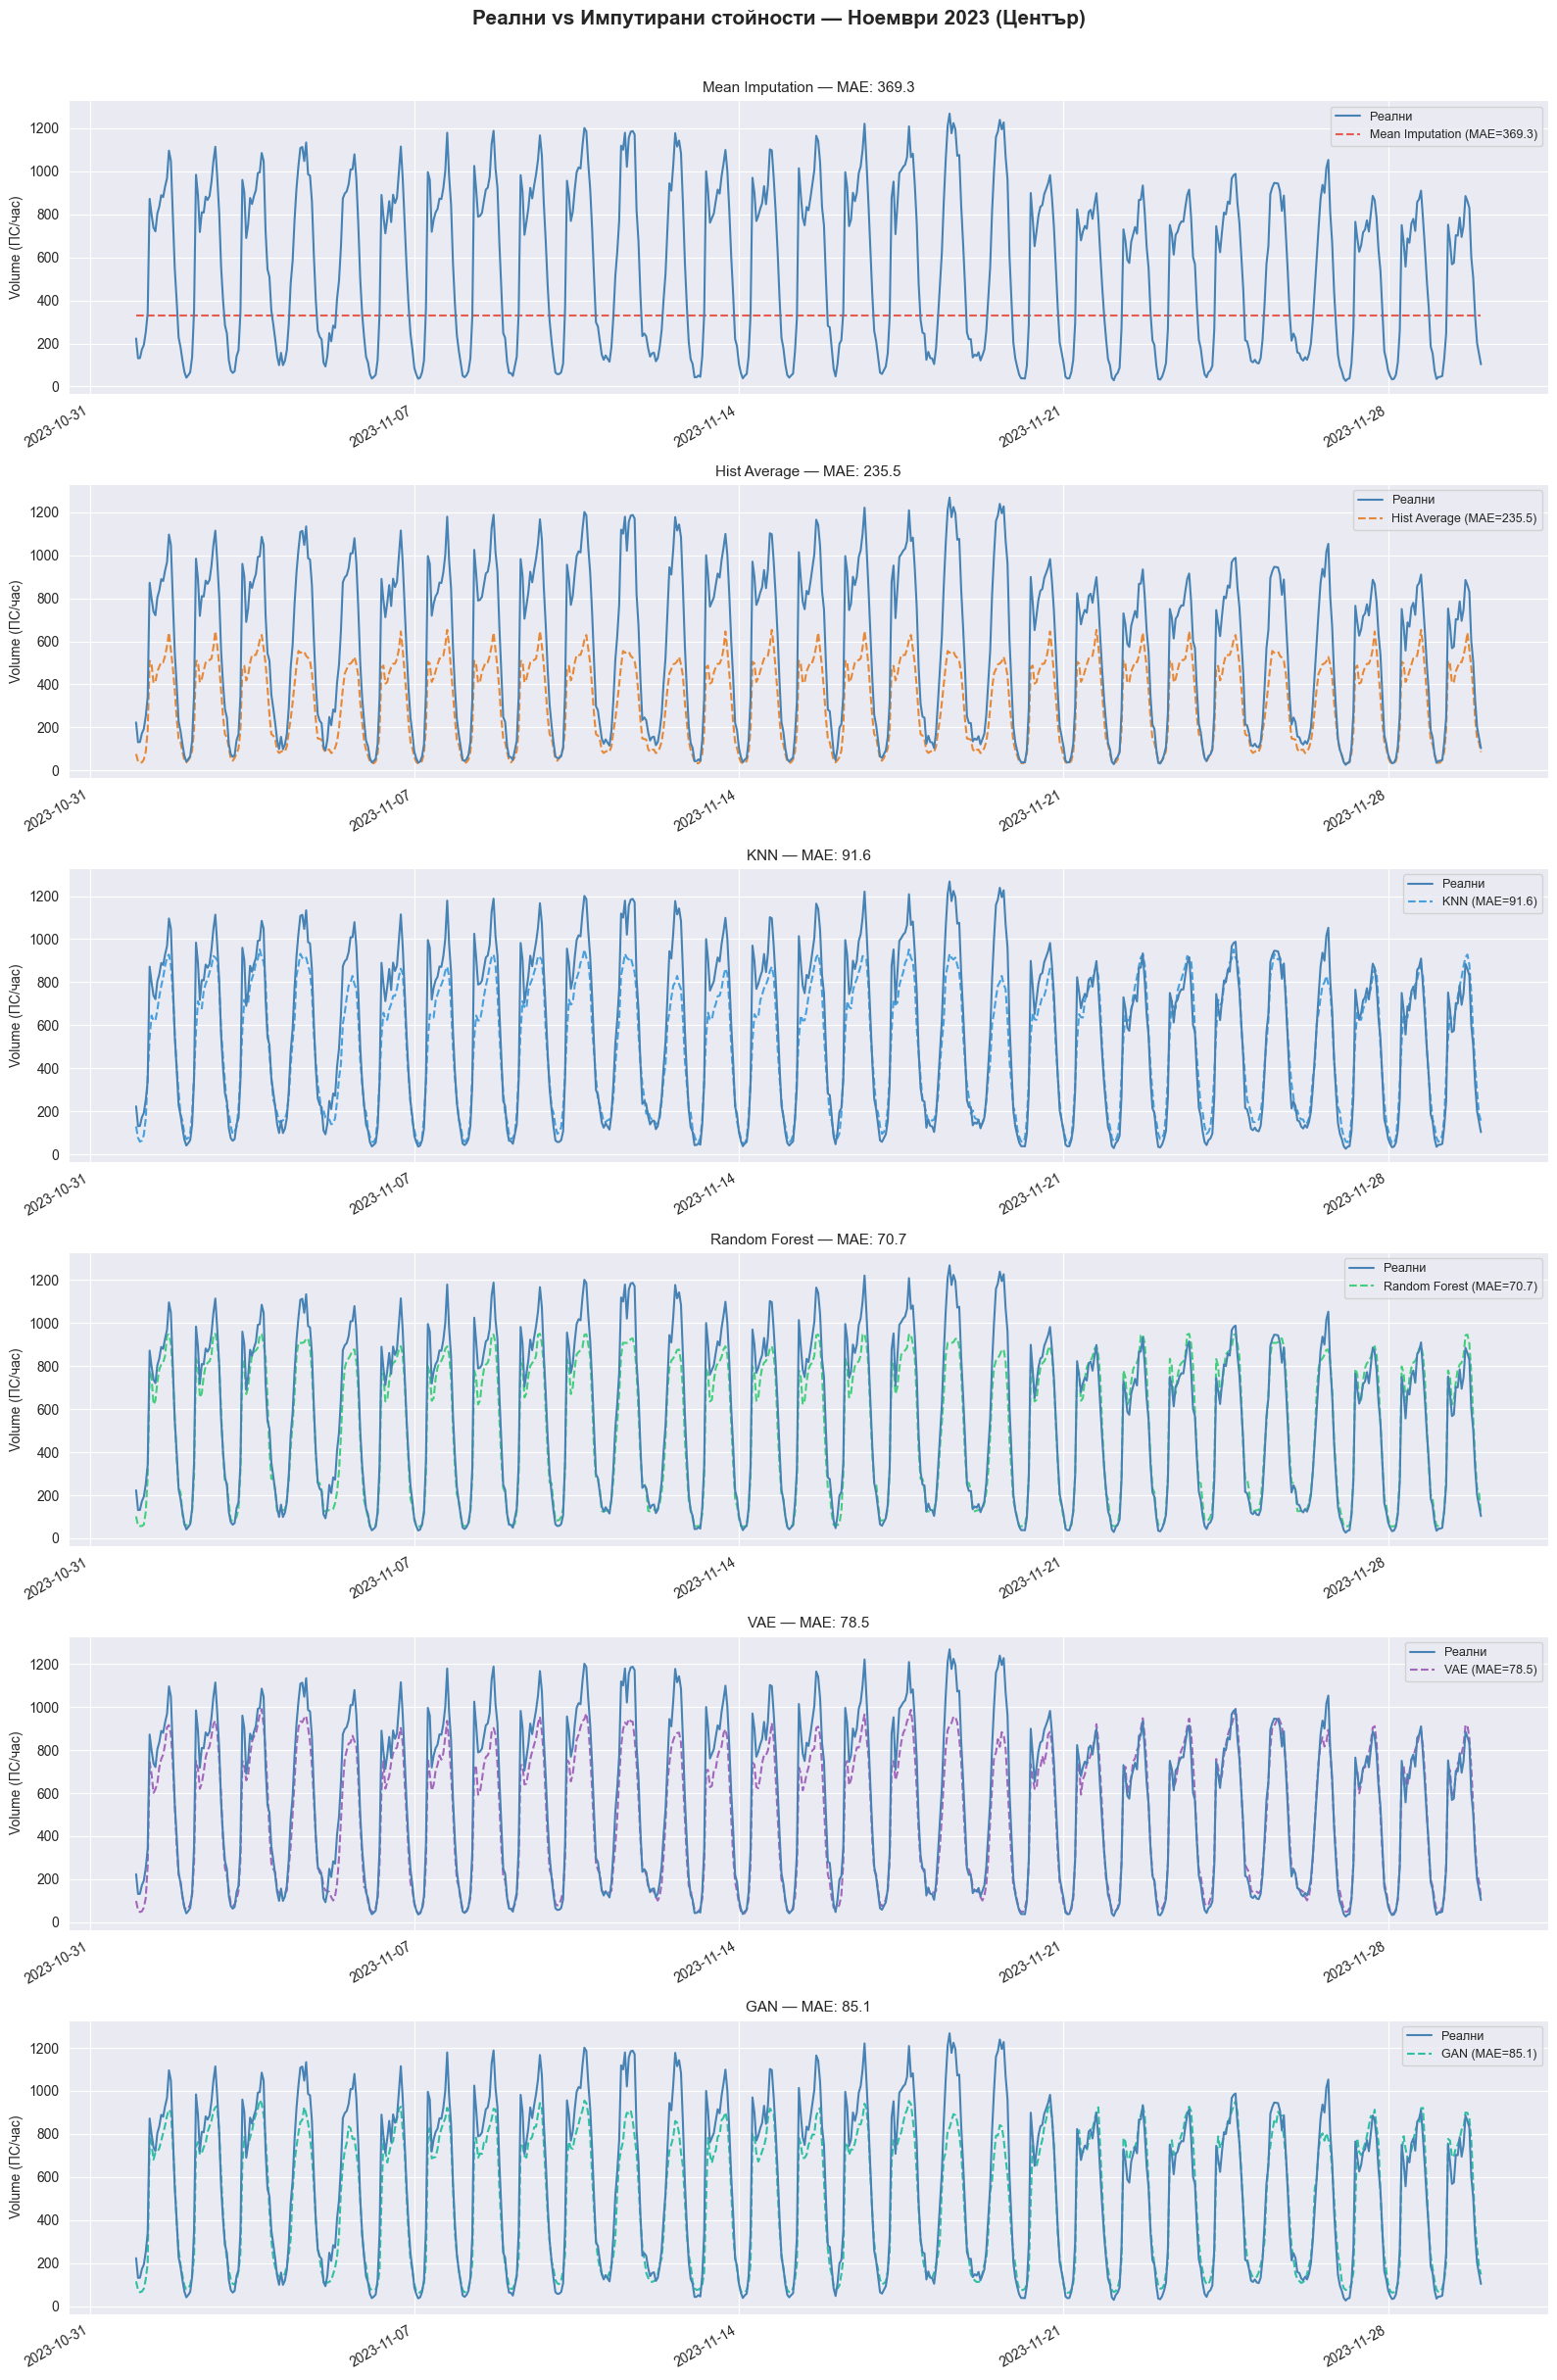

In [12]:
# Визуализация — всички 6 метода
method_info = [
    ("vol_mean", "Mean Imputation",  "#e74c3c"),
    ("vol_hist", "Hist Average",     "#e67e22"),
    ("vol_knn",  "KNN",              "#3498db"),
    ("vol_rf",   "Random Forest",    "#2ecc71"),
    ("vol_vae",  "VAE",              "#9b59b6"),
    ("vol_gan",  "GAN",              "#1abc9c"),
]

fig, axes = plt.subplots(6, 1, figsize=(16, 24))
fig.suptitle("Реални vs Импутирани стойности — Ноември 2023 (Център)",
             fontsize=15, fontweight="bold", y=1.01)

for ax, (col, label, color) in zip(axes, method_info):
    mae = np.mean(np.abs(test_center["volume_true"] - test_center[col]))
    ax.plot(test_center["datetime"], test_center["volume_true"],
            color="steelblue", linewidth=1.5, label="Реални", zorder=5)
    ax.plot(test_center["datetime"], test_center[col],
            color=color, linewidth=1.5, linestyle="--",
            label=f"{label} (MAE={mae:.1f})", alpha=0.9)
    ax.set_ylabel("Volume (ПС/час)")
    ax.set_title(f"{label} — MAE: {mae:.1f}", fontsize=11)
    ax.legend(loc="upper right", fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("comparison_all_methods_timeseries.png", 
            dpi=150, bbox_inches="tight")
plt.show()